# Idea 5 - The Bounty and the Spread

**The claim (Second Machine Age, ch. 9 and 11).** Digital technology produces
bounty and spread at the same time. Output per person keeps rising while the
typical household stops sharing in it. The notes record 1999 as the peak year
for real median household income, Bernstein's finding that productivity and
employment decoupled in the 1990s, and Acemoglu and Autor's wage series by
education level.

**The methodological problem this notebook exists to handle.** The
productivity-versus-pay gap is the most contested chart in American economics,
and a large part of the dispute is about deflators. Output per hour is
deflated by the prices of what workers *produce*; real compensation is usually
deflated by the prices of what workers *consume*. Those two indexes diverge, so
a gap appears even when labour's share of output has not moved at all.

Feldstein made this objection in 2008 and Stansbury and Summers worked through
it in 2017. A version of the chart that ignores it is easy to attack. So this
notebook draws the gap twice, once each way, and separates what is measurement
from what is real.

**The five questions.**

1. Is there a bounty? Output per person against the income of the household in
   the middle.
2. Is the pay gap an artefact of deflator choice, or does it survive?
3. Did productivity and employment come apart, as Bernstein found?
4. Where did the spread land? Wages by education.
5. How much of the gap between average and typical is simple skew?

**Data.** FRED throughout, with every series chosen from a printed candidate
list rather than hard-coded, since this notebook needs more series than any
previous one and FRED identifiers retire.

In [2]:
import sys, pathlib, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import stacklib as sl
importlib.reload(sl)

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("05_the_bounty_and_the_spread")
KEYS = sl.load_keys()
sl.apply_theme()
FRED = sl.require(KEYS, "FRED")

BASE = 1973          # the year the postwar pattern is usually said to break
def annual(s):
    a = s.groupby(s.index.year).mean(); a.index = a.index.astype(int); return a
def index_to(s, base=BASE):
    s = s.dropna()
    anchor = base if base in s.index else int(s.index.min())
    if anchor != base:
        print("NOTE  series starts %d; indexed there instead of %d" % (anchor, base))
    return s / s.loc[anchor] * 100

stacklib version: 0.4.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## 1. Find the series before using them

Read these printouts. Every identifier used below is chosen from them, and the
fetch reports which candidate resolved.

In [3]:
for term in ["real median household income",
             "mean household income",
             "nonfarm business sector real output per hour",
             "nonfarm business sector compensation per hour",
             "nonfarm business implicit price deflator",
             "median usual weekly earnings education"]:
    print("=== %s ===" % term)
    df = sl.fred_search(term, FRED, limit=6)
    print(df.to_string(index=False) if len(df) else "(nothing)")
    print()

=== real median household income ===
             id                                             title freq          units from   to  popularity
  MEHOINUSA672N Real Median Household Income in the United States    A 2024 C-CPI-U $ 1984 2024          83
MEHOINUSHIA672N            Real Median Household Income in Hawaii    A 2024 C-CPI-U $ 1984 2024          50
MEHOINUSCAA672N        Real Median Household Income in California    A 2024 C-CPI-U $ 1984 2024          34
MEHOINUSNYA672N          Real Median Household Income in New York    A 2024 C-CPI-U $ 1984 2024          33
MEHOINUSTXA672N             Real Median Household Income in Texas    A 2024 C-CPI-U $ 1984 2024          31
MEHOINUSFLA672N           Real Median Household Income in Florida    A 2024 C-CPI-U $ 1984 2024          29

=== mean household income ===
                id                                                                                              title freq             units from   to  popularity
            P

In [4]:
def get(candidates, label, **kw):
    sid, s = sl.fred_first_available(candidates, FRED, cache_dir=DIRS["data"], **kw)
    print("  %-26s -> %s" % (label, sid))
    return sid, annual(s)

print("resolving series:")
gdppc_id, GDPPC   = get(["A939RX0Q048SBEA"], "real GDP per capita")
medhh_id, MEDHH   = get(["MEHOINUSA672N"], "real median household income")
prod_id,  PROD    = get(["OPHNFB", "OPHPBS"], "output per hour")
compr_id, COMPR   = get(["COMPRNFB"], "real compensation (CPI)")
compn_id, COMPN   = get(["COMPNFB"], "compensation per hour (nominal)")
defl_id,  DEFL    = get(["IPDNBS", "GDPDEF"], "output price deflator")
emp_id,   EMP     = get(["PAYEMS", "USPRIV"], "employment")
cpi_id,   CPI     = get(["CPIAUCSL"], "consumer prices")

resolving series:
FRED A939RX0Q048SBEA: 318 obs, 1947-01-01-2026-04-01
  real GDP per capita        -> A939RX0Q048SBEA
FRED MEHOINUSA672N: 41 obs, 1984-01-01-2024-01-01
  real median household income -> MEHOINUSA672N
FRED OPHNFB: 318 obs, 1947-01-01-2026-04-01
  output per hour            -> OPHNFB
FRED COMPRNFB: 318 obs, 1947-01-01-2026-04-01
  real compensation (CPI)    -> COMPRNFB
FRED COMPNFB: 318 obs, 1947-01-01-2026-04-01
  compensation per hour (nominal) -> COMPNFB
FRED IPDNBS: 318 obs, 1947-01-01-2026-04-01
  output price deflator      -> IPDNBS
FRED PAYEMS: 1052 obs, 1939-01-01-2026-08-01
  employment                 -> PAYEMS
FRED CPIAUCSL: 954 obs, 1947-01-01-2026-07-01
  consumer prices            -> CPIAUCSL


## Figure 1 - The bounty and the spread

Output per person against the income of the household in the middle, indexed to
a common year so the comparison is of growth rather than levels.

NOTE  series starts 1984; indexed there instead of 1973
saved -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\figures\fig1_bounty_and_spread.png


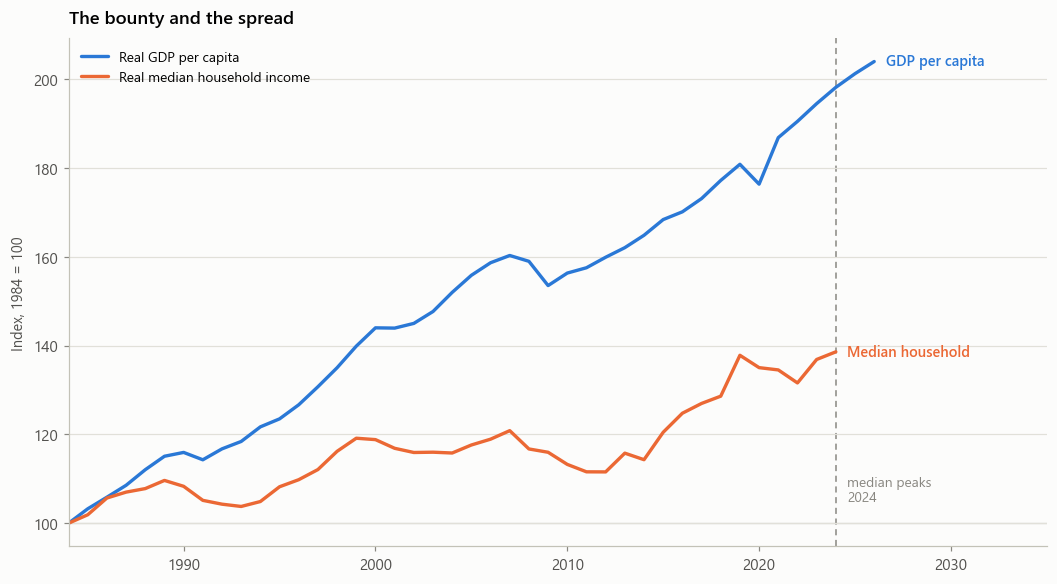

since 1984: GDP per capita +104%, median household income +39%
real median household income peaked in 2024 at $83,730


In [5]:
g, m = index_to(GDPPC), index_to(MEDHH)
common_start = max(g.index.min(), m.index.min())
g, m = g[g.index >= common_start], m[m.index >= common_start]
g, m = g / g.iloc[0] * 100, m / m.iloc[0] * 100

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(g.index, g.values, color=sl.PALETTE[0], lw=2.2, label="Real GDP per capita")
ax.plot(m.index, m.values, color=sl.PALETTE[1], lw=2.2, label="Real median household income")
sl.label_last(ax, g, "GDP per capita", sl.PALETTE[0])
sl.label_last(ax, m, "Median household", sl.PALETTE[1])
ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
peak = int(MEDHH.idxmax())
ax.axvline(peak, color=sl.INK["muted"], lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.text(peak + 0.6, 105, "median peaks\n%d" % peak, fontsize=9, color=sl.INK["muted"])
ax.set_ylabel("Index, %d = 100" % common_start)
ax.set_xlim(common_start, g.index.max() + 9)
ax.set_title("The bounty and the spread")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig1_bounty_and_spread", DIRS)
plt.show()
print("since %d: GDP per capita +%.0f%%, median household income +%.0f%%"
      % (common_start, g.iloc[-1] - 100, m.iloc[-1] - 100))
print("real median household income peaked in %d at $%s"
      % (peak, format(float(MEDHH.max()), ",.0f")))

## Figure 2 - The gap, drawn twice

The three lines are output per hour, compensation per hour deflated by the
prices of what workers produce, and compensation per hour deflated by the
prices of what workers buy. The distance between the two compensation lines is
entirely a deflator choice. The distance that remains between productivity and
the *output-deflated* line is the part no deflator argument can explain away.

saved -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\figures\fig2_deflator_decomposition.png


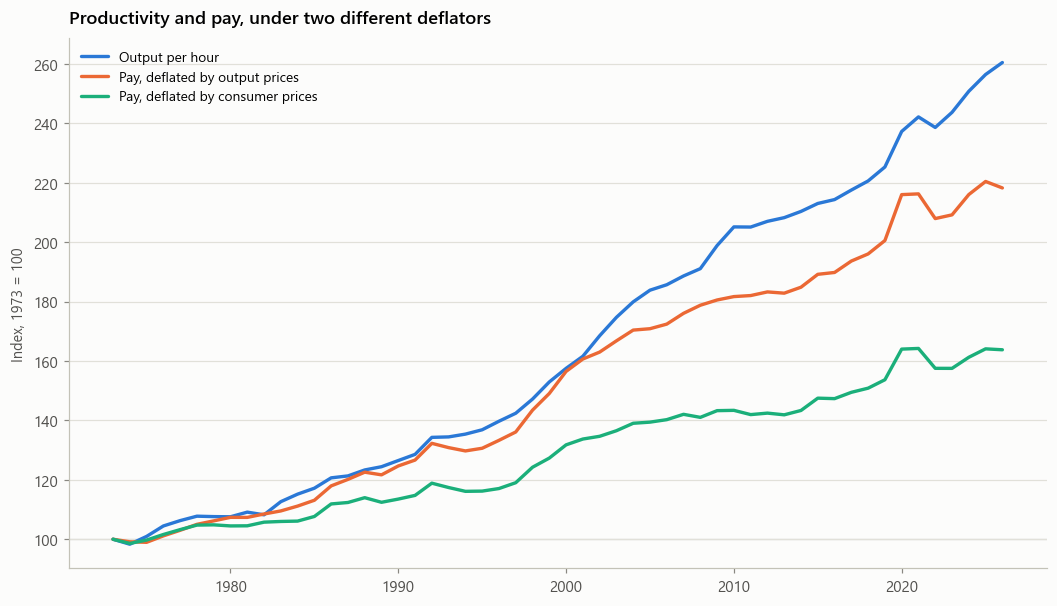


By 2026, indexed to 1973 = 100:
   productivity            260.5
   pay, output deflator    218.3   gap 42.2 points
   pay, consumer deflator  163.8   gap 96.7 points

   56% of the headline gap is deflator choice; 44% survives it.


In [6]:
comp_output_defl = (COMPN / DEFL).dropna()
start = max(PROD.dropna().index.min(), comp_output_defl.index.min(),
            COMPR.dropna().index.min(), BASE)
P_ = index_to(PROD[PROD.index >= start], start)
C_out = index_to(comp_output_defl[comp_output_defl.index >= start], start)
C_cpi = index_to(COMPR[COMPR.index >= start], start)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
for s, name, color in [(P_, "Output per hour", sl.PALETTE[0]),
                       (C_out, "Pay, deflated by output prices", sl.PALETTE[1]),
                       (C_cpi, "Pay, deflated by consumer prices", sl.PALETTE[2])]:
    ax.plot(s.index, s.values, color=color, lw=2.2, label=name)
ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.set_ylabel("Index, %d = 100" % start)
ax.set_title("Productivity and pay, under two different deflators")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig2_deflator_decomposition", DIRS)
plt.show()

naive_gap = float(P_.iloc[-1] - C_cpi.iloc[-1])
real_gap = float(P_.iloc[-1] - C_out.iloc[-1])
print("\nBy %d, indexed to %d = 100:" % (P_.index[-1], start))
print("   productivity            %.1f" % P_.iloc[-1])
print("   pay, output deflator    %.1f   gap %.1f points" % (C_out.iloc[-1], real_gap))
print("   pay, consumer deflator  %.1f   gap %.1f points" % (C_cpi.iloc[-1], naive_gap))
print("\n   %.0f%% of the headline gap is deflator choice; %.0f%% survives it."
      % (100 * (naive_gap - real_gap) / naive_gap, 100 * real_gap / naive_gap))

## Figure 3 - Productivity and employment

Bernstein's finding, as the notes record it: the two came apart in the 1990s.
The book's Figure 11.1 runs to 2011; this extends it.

saved -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\figures\fig3_productivity_and_employment.png


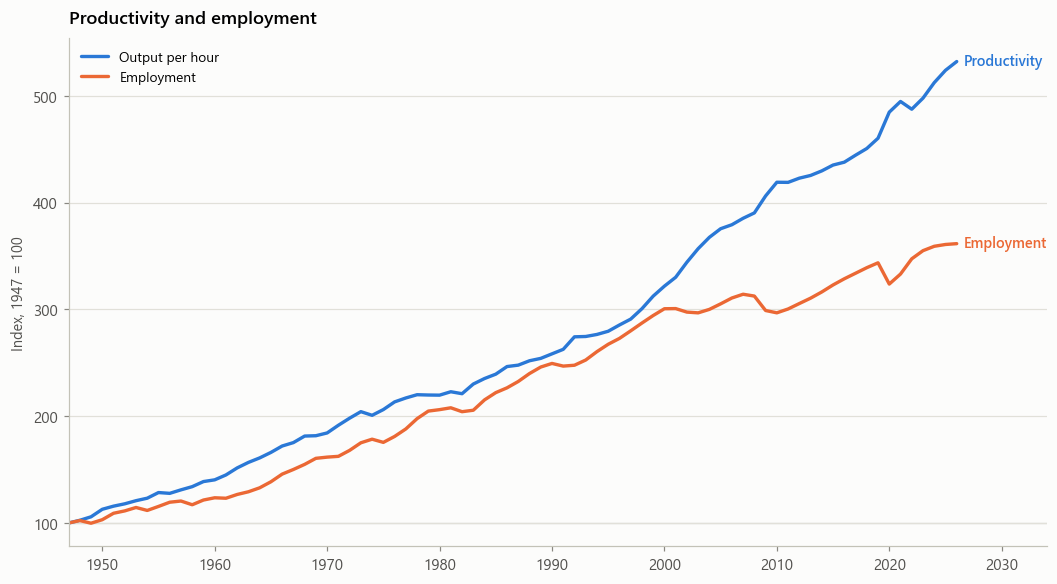

In [7]:
p2, e2 = index_to(PROD, 1972), index_to(EMP, 1972)
st = max(p2.index.min(), e2.index.min())
p2, e2 = p2[p2.index >= st], e2[e2.index >= st]
p2, e2 = p2 / p2.iloc[0] * 100, e2 / e2.iloc[0] * 100

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(p2.index, p2.values, color=sl.PALETTE[0], lw=2.2, label="Output per hour")
ax.plot(e2.index, e2.values, color=sl.PALETTE[1], lw=2.2, label="Employment")
sl.label_last(ax, p2, "Productivity", sl.PALETTE[0])
sl.label_last(ax, e2, "Employment", sl.PALETTE[1])
ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.set_ylabel("Index, %d = 100" % st)
ax.set_xlim(st, p2.index.max() + 8)
ax.set_title("Productivity and employment")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig3_productivity_and_employment", DIRS)
plt.show()

## Figure 4 - Where the spread landed

The notes reproduce Acemoglu and Autor's wages by education. CPS median usual
weekly earnings are the closest public series. Deflated by consumer prices,
because these are wages people spend.

FRED LEU0252916800Q: 105 obs, 2000-01-01-2026-04-01
  Less than high school    -> LEU0252916800Q
FRED LEU0252917300Q: 105 obs, 2000-01-01-2026-04-01
  High school, no college  -> LEU0252917300Q
FRED LEU0252918500Q: 105 obs, 2000-01-01-2026-04-01
  Some college             -> LEU0252918500Q
FRED LEU0252918900Q: 105 obs, 2000-01-01-2026-04-01
  Bachelor's and higher    -> LEU0252918900Q
saved -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\figures\fig4_earnings_by_education.png


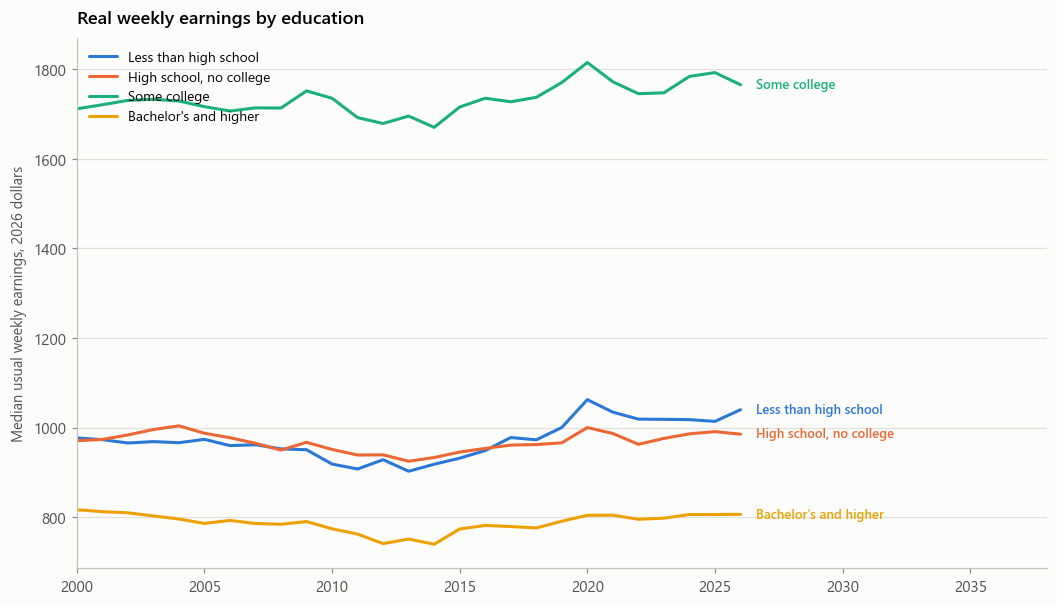

In [8]:
EDU_CANDIDATES = {
    "Less than high school": ["LEU0252916800Q", "LEU0252916700Q"],
    "High school, no college": ["LEU0252917300Q", "LEU0252917200Q"],
    "Some college": ["LEU0252918500Q", "LEU0252918400Q"],
    "Bachelor's and higher": ["LEU0252918900Q", "LEU0252919000Q"],
}
edu, edu_ids = {}, {}
for label, cands in EDU_CANDIDATES.items():
    try:
        sid, s = sl.fred_first_available(cands, FRED, cache_dir=DIRS["data"])
        edu[label] = annual(s); edu_ids[label] = sid
        print("  %-24s -> %s" % (label, sid))
    except Exception as e:
        print("  %-24s unavailable (%s)" % (label, str(e)[:60]))

if edu:
    cpi_idx = CPI / CPI.loc[CPI.index.max()] * 100
    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    for (label, s), color in zip(edu.items(), sl.PALETTE[:4]):
        real = (s / cpi_idx.reindex(s.index) * 100).dropna()
        ax.plot(real.index, real.values, color=color, lw=2.0, label=label)
        sl.label_last(ax, real, label, color, fontsize=8.5)
    ax.set_ylabel("Median usual weekly earnings, %d dollars" % int(CPI.index.max()))
    ax.set_xlim(min(s.index.min() for s in edu.values()),
                max(s.index.max() for s in edu.values()) + 12)
    ax.set_title("Real weekly earnings by education")
    ax.legend(loc="upper left")
    sl.save_fig(fig, "fig4_earnings_by_education", DIRS)
    plt.show()
else:
    print("No education series resolved; skipping Figure 4.")

## Figure 5 - Average against typical

When a distribution is skewed, the mean rises faster than the median even if
nothing else changes. The ratio between them is a crude but direct measure of
how much of the bounty sits in the upper tail.

FRED MAFAINUSA672N: 72 obs, 1953-01-01-2024-01-01
  real mean family income    -> MAFAINUSA672N
saved -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\figures\fig5_mean_vs_median.png


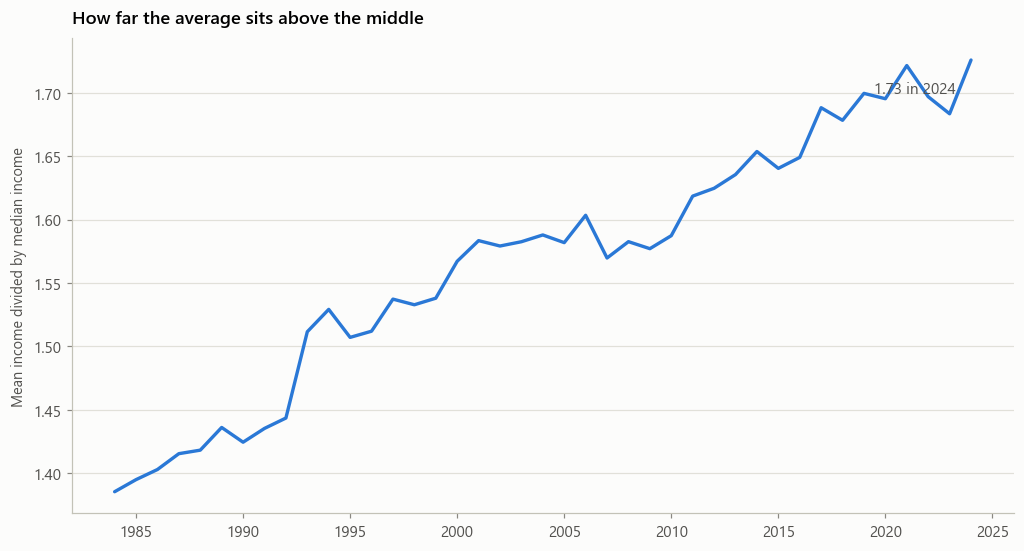

mean/median ratio: 1.385 in 1984, 1.726 in 2024


In [9]:
mean_id, MEANHH, ratio = None, None, None
try:
    mean_id, MEANHH = get(["MAFAINUSA672N"], "real mean family income")
    common = MEDHH.dropna().index.intersection(MEANHH.dropna().index)
    ratio = (MEANHH.loc[common] / MEDHH.loc[common]).dropna()
    fig, ax = plt.subplots(figsize=(9.2, 4.9))
    ax.plot(ratio.index, ratio.values, color=sl.PALETTE[0], lw=2.2)
    ax.set_ylabel("Mean income divided by median income")
    ax.set_title("How far the average sits above the middle")
    ax.annotate("%.2f in %d" % (ratio.iloc[-1], ratio.index[-1]),
                xy=(ratio.index[-1], ratio.iloc[-1]), xytext=(-10, -22),
                textcoords="offset points", ha="right",
                color=sl.INK["secondary"], fontsize=10)
    sl.save_fig(fig, "fig5_mean_vs_median", DIRS)
    plt.show()
    print("mean/median ratio: %.3f in %d, %.3f in %d"
          % (ratio.iloc[0], ratio.index[0], ratio.iloc[-1], ratio.index[-1]))
except Exception as e:
    print("Mean income series unavailable (%s). Skipping Figure 5." % str(e)[:90])
    print("If this fails, the Census API is the fallback and we will add it next round.")

## 2. Bank the numbers

In [10]:
payload = {
    "stacklib_version": sl.__version__,
    "series_used": {"gdp_per_capita": gdppc_id, "median_household": medhh_id,
                    "productivity": prod_id, "real_comp_cpi": compr_id,
                    "comp_nominal": compn_id, "output_deflator": defl_id,
                    "employment": emp_id, "cpi": cpi_id,
                    "mean_household": mean_id, "education": edu_ids},
    "index_base_year": int(common_start),
    "gdp_per_capita_growth_pct": float(g.iloc[-1] - 100),
    "median_household_growth_pct": float(m.iloc[-1] - 100),
    "median_household_peak_year": int(peak),
    "median_household_peak_value": float(MEDHH.max()),
    "median_household_latest": float(MEDHH.dropna().iloc[-1]),
    "deflator_analysis": {
        "start_year": int(start), "end_year": int(P_.index[-1]),
        "productivity_index": float(P_.iloc[-1]),
        "pay_output_deflated_index": float(C_out.iloc[-1]),
        "pay_cpi_deflated_index": float(C_cpi.iloc[-1]),
        "headline_gap_points": naive_gap,
        "gap_surviving_deflator_points": real_gap,
        "share_of_gap_from_deflator_pct": 100 * (naive_gap - real_gap) / naive_gap,
    },
    "mean_median_ratio": (None if ratio is None else
                          {"first_year": int(ratio.index[0]), "first": float(ratio.iloc[0]),
                           "last_year": int(ratio.index[-1]), "last": float(ratio.iloc[-1])}),
}
sl.write_findings(payload, DIRS)
pd.DataFrame({"productivity": P_, "pay_output_deflated": C_out,
              "pay_cpi_deflated": C_cpi}).to_csv(
    pathlib.Path(DIRS["findings"]) / "productivity_pay_gap.csv")
print("\nDone. Figures in figures/, numbers in findings/.")

findings -> C:\Users\91838\Downloads\Stack_Article\05_the_bounty_and_the_spread\findings\headline_numbers.json

Done. Figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **Households are not workers.** Median household income moves with household
   size, with the number of earners per household, and with transfers and
   taxes. Some of the flatness in Figure 1 is demographic rather than a story
   about pay.
2. **Compensation is not wages.** The compensation series includes employer
   contributions to health insurance and pensions, which have grown faster than
   cash pay. A worker can receive more compensation and less money.
3. **The deflator argument cuts both ways.** Deflating pay by consumer prices
   is the right choice if the question is what workers can buy. It is the wrong
   choice if the question is whether pay tracks output. The two questions have
   different answers and the article should pick one and say which.
4. **CPS earnings by education are top-coded and composition-shifting.** The
   share of workers holding each credential changed enormously across this
   period, so the lines compare different populations at different dates. This
   is why Acemoglu and Autor use composition-adjusted series, which are not
   public in this form.
5. **Mean over median is a coarse inequality measure.** It moves with the whole
   upper tail and cannot separate the top 1 percent from the top 20.

**Send back:** the five PNGs, the FRED candidate printouts from cell 4, the
resolution list showing which identifier each series used, the deflator
decomposition printout, and `findings/headline_numbers.json`. The deflator
numbers are the ones I most want to see.